# Bank Customer Churn Prediction using Artificial Neural Networks (ANN)

This notebook demonstrates an end-to-end machine learning workflow using Keras and TensorFlow to predict bank customer churn. It includes:
1. **Data Preprocessing**: Handling categorical variables and feature scaling.
2. **Baseline Model**: A simple neural network to establish a performance benchmark.
3. **Optimized Deep Learning Model**: An enhanced multi-layer neural network utilizing Dropout regularization and Early Stopping to improve accuracy and prevent overfitting.
4. **Performance Visualization**: Loss and Accuracy tracking.

In [2]:
import pandas as pd
df= pd.read_csv("/content/Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 1. Exploratory Data Analysis & Feature Selection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [6]:
df['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [7]:
df['Gender'].value_counts

<bound method IndexOpsMixin.value_counts of 0       Female
1       Female
2       Female
3       Female
4       Female
         ...  
9995      Male
9996      Male
9997    Female
9998      Male
9999    Female
Name: Gender, Length: 10000, dtype: object>

In [8]:
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)

In [9]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
pd.get_dummies(df[['Geography', 'Gender']], drop_first=True)

,Geography_Germany,Geography_Spain,Gender_Male
0,False,False,False
1,False,True,False
2,False,False,False
3,False,False,False
4,False,True,False
...,...,...,...
9995,False,False,True
9996,False,False,True
9997,False,False,False
9998,True,False,True


In [11]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [12]:
x = df.drop(columns =['Exited'])
y = df['Exited']
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2)

## 2. Feature Encoding & Scaling

In [13]:
x

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10
...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77
9997,709,France,Female,36,7,0.00,1,0,1,42085.58
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52


In [14]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Convert categorical columns 'Geography' and 'Gender' to dummy variables in both train and test sets
x_train = pd.get_dummies(x_train, columns=['Geography', 'Gender'], drop_first=True)
x_test = pd.get_dummies(x_test, columns=['Geography', 'Gender'], drop_first=True)

# Ensure both sets have the exact same columns after dummy encoding
x_train, x_test = x_train.align(x_test, join='left', axis=1, fill_value=0)

# Scale the features
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [15]:
x_train

array([[-1.00775305, -0.66164266,  0.68741696, ..., -0.58177669,
        -0.57581067,  0.91762992],
       [ 0.30236244,  1.82115858,  1.03203005, ...,  1.71887259,
        -0.57581067,  0.91762992],
       [ 2.0803763 , -0.27967324, -1.03564849, ..., -0.58177669,
         1.73668197, -1.08976394],
       ...,
       [-0.25911563, -1.4255815 , -1.38026158, ..., -0.58177669,
        -0.57581067, -1.08976394],
       [ 1.56048921, -0.08868852,  1.37664314, ..., -0.58177669,
         1.73668197,  0.91762992],
       [-0.95576434,  0.57975796, -0.34642231, ..., -0.58177669,
         1.73668197,  0.91762992]])

In [16]:
!pip install tensorflow

In [17]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

## 3. Baseline Neural Network Model

In [18]:
model = Sequential()

model.add(Dense(3, activation='relu', input_dim =11))
model.add(Dense(3, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52 (208.00 B)

 Trainable params: 52 (208.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(loss= 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [21]:
model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=['accuracy'])
hist = model.fit(x_train, y_train, batch_size=50, epochs=50, validation_split=0.2)

Epoch 1/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7981 - loss: 0.5623 - val_accuracy: 0.7994 - val_loss: 0.5069
Epoch 2/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7981 - loss: 0.4908 - val_accuracy: 0.7994 - val_loss: 0.4755
Epoch 3/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7981 - loss: 0.4684 - val_accuracy: 0.7994 - val_loss: 0.4617
Epoch 4/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7981 - loss: 0.4571 - val_accuracy: 0.7994 - val_loss: 0.4527
Epoch 5/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7981 - loss: 0.4505 - val_accuracy: 0.7994 - val_loss: 0.4467
Epoch 6/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7981 - loss: 0.4453 - val_accuracy: 0.7994 - val_loss: 0.4419
Epoch 7/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7981 - loss: 0.4413 - val_accuracy: 0.7994 - val_loss: 0.4375
Epoch 8/50
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7981 - loss: 0.4378 - val_accuracy: 0

In [22]:
model.layers[0].get_weights()

[array([[ 0.08455493,  0.05495182,  0.1368247 ],
        [-1.3741856 , -0.05624462, -0.6416998 ],
        [ 0.01744729,  0.01634553,  0.12363327],
        [-0.24342014, -0.53924024, -0.29599065],
        [-0.25902048, -1.23982   , -0.28188622],
        [-0.06664158, -0.05708684,  0.08068395],
        [-0.8944001 , -0.8565276 ,  0.89832574],
        [-0.01727153, -0.03896708, -0.03232099],
        [-0.15626362,  0.30266258, -0.15943538],
        [-0.28375116, -0.2463234 ,  0.02525223],
        [ 0.23011638,  0.07302094,  0.24738145]], dtype=float32),
 array([1.1481209 , 0.35009402, 0.61563677], dtype=float32)]

In [23]:
y_log =model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [24]:
import numpy as np
y_log = model.predict(x_test)
y_pred = np.where(y_log > 0.5, 1, 0)
y_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]])

In [25]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.827

## 4. Optimized Neural Network (Enhanced Accuracy)

In [26]:
import matplotlib.pyplot as plt


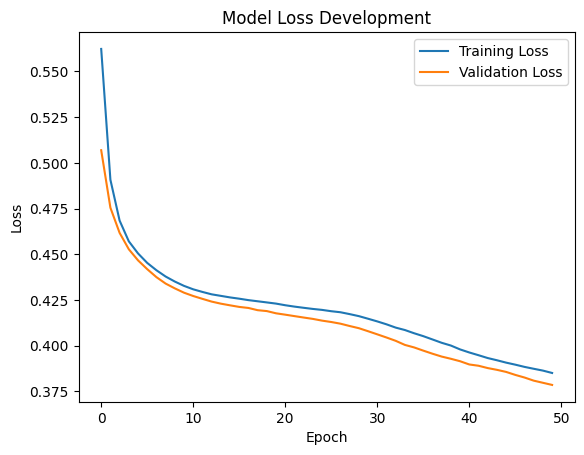

In [27]:
plt.plot(hist.history['loss'], label='Training Loss')
plt.plot(hist.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Development')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [28]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Design an optimized deeper neural network
enhanced_model = Sequential([
    Dense(64, activation='relu', input_dim=11),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compile the enhanced model
enhanced_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Use early stopping to prevent overfitting and capture the best weights
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Fit the enhanced model
enhanced_history = enhanced_model.fit(
    x_train, y_train,
    batch_size=32,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7930 - loss: 0.4831 - val_accuracy: 0.8250 - val_loss: 0.4185
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8181 - loss: 0.4311 - val_accuracy: 0.8338 - val_loss: 0.3949
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8288 - loss: 0.4030 - val_accuracy: 0.8438 - val_loss: 0.3698
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8380 - loss: 0.3878 - val_accuracy: 0.8531 - val_loss: 0.3598
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8452 - loss: 0.3688 - val_accuracy: 0.8556 - val_loss: 0.3496
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8475 - loss: 0.3679 - val_accuracy: 0.8556 - val_loss: 0.3437
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8500 - loss: 0.3555 - val_accuracy: 0.8581 - val_loss: 0.3425
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8564 - loss: 0.3496 - val_accuracy: 0.8619

In [29]:
# Evaluate the enhanced model on the test set
y_pred_prob = enhanced_model.predict(x_test)
y_pred_enhanced = np.where(y_pred_prob > 0.5, 1, 0)

enhanced_acc = accuracy_score(y_test, y_pred_enhanced)
print(f"Enhanced Model Test Accuracy: {enhanced_acc:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Enhanced Model Test Accuracy: 0.8560


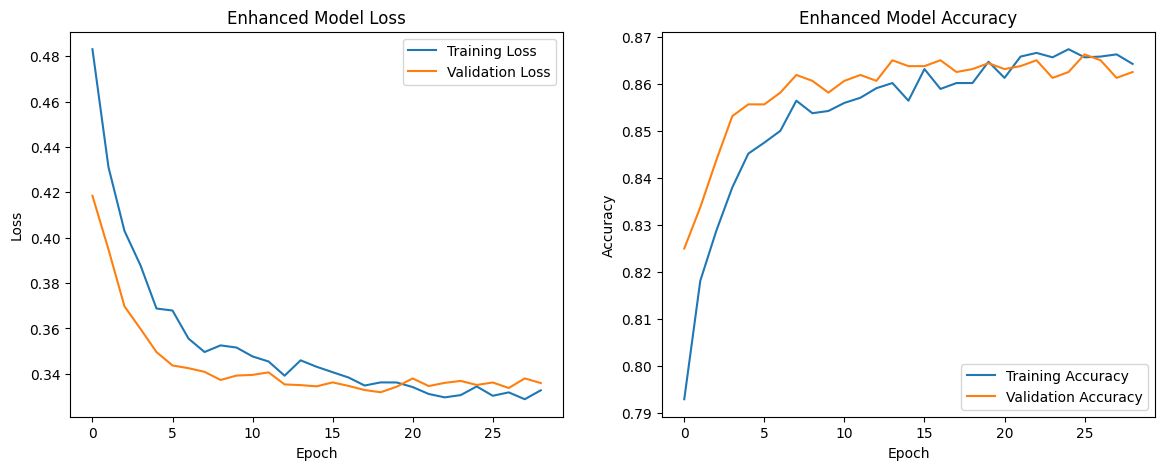

In [30]:
# Plot Training & Validation Loss and Accuracy side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Plot
ax1.plot(enhanced_history.history['loss'], label='Training Loss')
ax1.plot(enhanced_history.history['val_loss'], label='Validation Loss')
ax1.set_title('Enhanced Model Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Accuracy Plot
ax2.plot(enhanced_history.history['accuracy'], label='Training Accuracy')
ax2.plot(enhanced_history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_title('Enhanced Model Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()